In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## Homework 9: Theory Assignment 

**Problem 1**: Given discrete probability distributions $\left\{p_{k}\right\}_{k=1}^{C}$ and $\left\{q_{k}\right\}_{k=1}^{C}$, we define the *Kullback-Leibler distance* between the distributions, say $D_{KL}({\bf p}||{\bf q})$ to be 

$$
D_{KL}({\bf p}||{\bf q}) = \sum_{k=1}^{C}p_{k}\log\left(\frac{p_{k}}{q_{k}}\right)
$$

Note, we have $\lim_{x\rightarrow 0^{+}}x\log(x) = 0$ which is how we can work with distributions defined by one-hot encodings.  Given the above definition, show that maximum log-likelihood funciton, say $\mathcal{L}({\bf W},{\bf b})$ for $C$-label classification on training data $\left\{({\bf x}_{j},{\bf y}_{j})\right\}_{j=1}^{N_{D}}$ can be rewritten as 

$$
\mathcal{L}({\bf W},{\bf b}) = -\sum_{j=1}^{N_{D}} D_{KL}({\bf y}_{j}||\text{soft max}({\bf W}{\bf x}_{j}+{\bf b})).
$$

Remember, each label ${\bf y}_{j}$ is a one-hot encoded label and thus a very boring kind of probability distribution.  

### Answer

From before, we can write the maximum likelihood function as:

$$
\mathcal{L}({\bf W},{\bf b}) = \sum_{j=1}^{N_D} \sum_{l=1}^{C} y_{jl} \log(\text{soft max}(({\bf W} \bf{x}_j + \bf{b})_l))
$$

The Kullback-Leibler distance can be rewritten (using log properties):

$$
D_{KL}({\bf p}||{\bf q}) = \sum_{k=1}^{C}p_{k}\log\left(\frac{p_{k}}{q_{k}}\right) =  \sum_{k=1}^{C}p_{k}\log\left(p_{k}\right) - p_{k}\log\left(q_{k}\right)
$$

Assuming that ${\bf p}$ is a one-hot encoded distribution, the Kullback-Leibler distance becomes:

$$
D_{KL}({\bf p}||{\bf q}) = \sum_{k=1}^{C} -p_{k} \log\left(q_{k}\right) \\
= - \sum_{k=1}^{C} p_{k} \log\left(q_{k}\right) 
$$

since the first term is 0 both when $p_{k}$ is 0 and when it is 1, and thus it disappears from the summation.

With this in hand, we can rewrite our maximum log likelihood equation as:

$$
\begin{aligned}
\mathcal{L}({\bf W},{\bf b}) = \sum_{j=1}^{N_D} \sum_{l=1}^{C} y_{jl} \log(\text{soft max}(({\bf W} \bf{x}_j + \bf{b})_l)) \\
= - \sum_{j=1}^{N_D} - \sum_{l=1}^{C} y_{jl} \log(\text{soft max}(({\bf W} \bf{x}_j + \bf{b})_l)) \\
= -\sum_{j=1}^{N_{D}} D_{KL}({\bf y}_{j}||\text{soft max}({\bf W}{\bf x}_{j}+{\bf b}))
\end{aligned}
$$

**Problem 2**: For discrete distributions ${\bf p}$ and ${\bf q}$, show that if there exists at least one index $k$ such that $q_{k}=0$ but $p_{k}>0$, then $D_{K}({\bf p},{\bf q}) = \infty$.  What happens if we have at least one $k$ such that $q_{k}>0$ but $p_{k}=0$?  How does this distinction essentially prove that $d_{KL}({\bf p}||{\bf q})\neq d_{KL}({\bf q}||{\bf p})$?   

### Answer

Recall that for discrete distributions,

$$
D_{KL}({\bf p}||{\bf q}) = \sum_{k=1}^{C}p_k\log\left(\frac{p_k}{q_k}\right),
$$

where we use the convention that $0\log(0/q_k)=0$ whenever $q_k>0$.

Suppose that there is an index $k_0$ such that $p_{k_0}>0$ but $q_{k_0}=0$.  The corresponding term is

$$
p_{k_0}\log\left(\frac{p_{k_0}}{q_{k_0}}\right)
=p_{k_0}\log\left(\frac{p_{k_0}}{0}\right)
=+\infty.
$$

More formally, if we replace $q_{k_0}=0$ by a positive number $\varepsilon$ and let $\varepsilon\downarrow 0$, then

$$
\lim_{\varepsilon\downarrow 0}p_{k_0}\log\left(\frac{p_{k_0}}{\varepsilon}\right)=+\infty,
$$

because $p_{k_0}>0$. For every other index $k\neq k_0$, the terms are finite provided $q_k>0$: if $p_k>0$, then $p_k\log(p_k/q_k)$ is finite, and if $p_k=0$, its contribution is defined to be $0$. Since the sum contains only finitely many such terms, adding these finite terms to one term equal to $+\infty$ still gives $+\infty$. Hence,

$$
\boxed{D_{KL}({\bf p}||{\bf q})=+\infty.}
$$

For a concrete example, let

$$
\widehat{\bf p}=\frac{1}{C}(1,1,\ldots,1),
\qquad
\widehat{\boldsymbol\delta}=\frac{1}{C-1}(0,1,\ldots,1).
$$

Then

$$
\begin{aligned}
D_{KL}(\widehat{\bf p}||\widehat{\boldsymbol\delta})
&=\frac{1}{C}\log\left(\frac{1/C}{0}\right)
+\sum_{k=2}^{C}\frac{1}{C}\log\left(\frac{1/C}{1/(C-1)}\right)\\
&=+\infty.
\end{aligned}
$$

Now reverse the order.  Since the first component of $\widehat{\boldsymbol\delta}$ is zero, its contribution is zero:

$$
0\log\left(\frac{0}{1/C}\right)=0.
$$

Therefore,

$$
\begin{aligned}
D_{KL}(\widehat{\boldsymbol\delta}||\widehat{\bf p})
&=0\log\left(\frac{0}{1/C}\right)
+\sum_{k=2}^{C}\frac{1}{C-1}\log\left(\frac{1/(C-1)}{1/C}\right)\\
&=\sum_{k=2}^{C}\frac{1}{C-1}\log\left(\frac{C}{C-1}\right)\\
&=(C-1)\frac{1}{C-1}\log\left(\frac{C}{C-1}\right)\\
&=\boxed{\log\left(\frac{C}{C-1}\right)}.
\end{aligned}
$$

Thus,

$$
D_{KL}(\widehat{\bf p}||\widehat{\boldsymbol\delta})=+\infty
\neq
\log\left(\frac{C}{C-1}\right)
=D_{KL}(\widehat{\boldsymbol\delta}||\widehat{\bf p}),
$$

which demonstrates that the KL divergence is not symmetric in general:

$$
\boxed{D_{KL}({\bf p}||{\bf q})\neq D_{KL}({\bf q}||{\bf p}).}
$$


**Problem 3** (Graduate/Extra Credit): We say a function $f:\mathbb{R}^{n} \rightarrow \mathbb{R}$ is *convex* if 

$$
f\left(\lambda {\bf x} + (1-\lambda) {\bf y}\right) \leq \lambda f({\bf x}) + (1-\lambda)f({\bf y}), ~ \lambda \in [0,1].
$$

3.1) Show that $f(x) = -\log (x)$ is convex.  

### Answer:

One way we can do this is by taking the second derivative f''(x). We know that a twice-differentiable function is convex on a interval if $f''(x) \leq 0$.

Hence (I'm assuming $\log (x) = \ln (x)$):

$$
f'(x) = -\frac{1}{x}, \qquad f''(x) = \frac{1}{x^2}.
$$

Since $x^2 > 0$ for all $x > 0$, we have

$$
f''(x) = \frac{1}{x^2} > 0, \quad \forall x \in (0,\infty).
$$

Therefore, $f(x) = -\ln(x)$ is strictly convex on $(0,\infty)$,
and hence convex.

Geometrically, we can also see that this is true by plotting -log(x) and connecting a line between two points, seeing that it lies above our function (see image below).

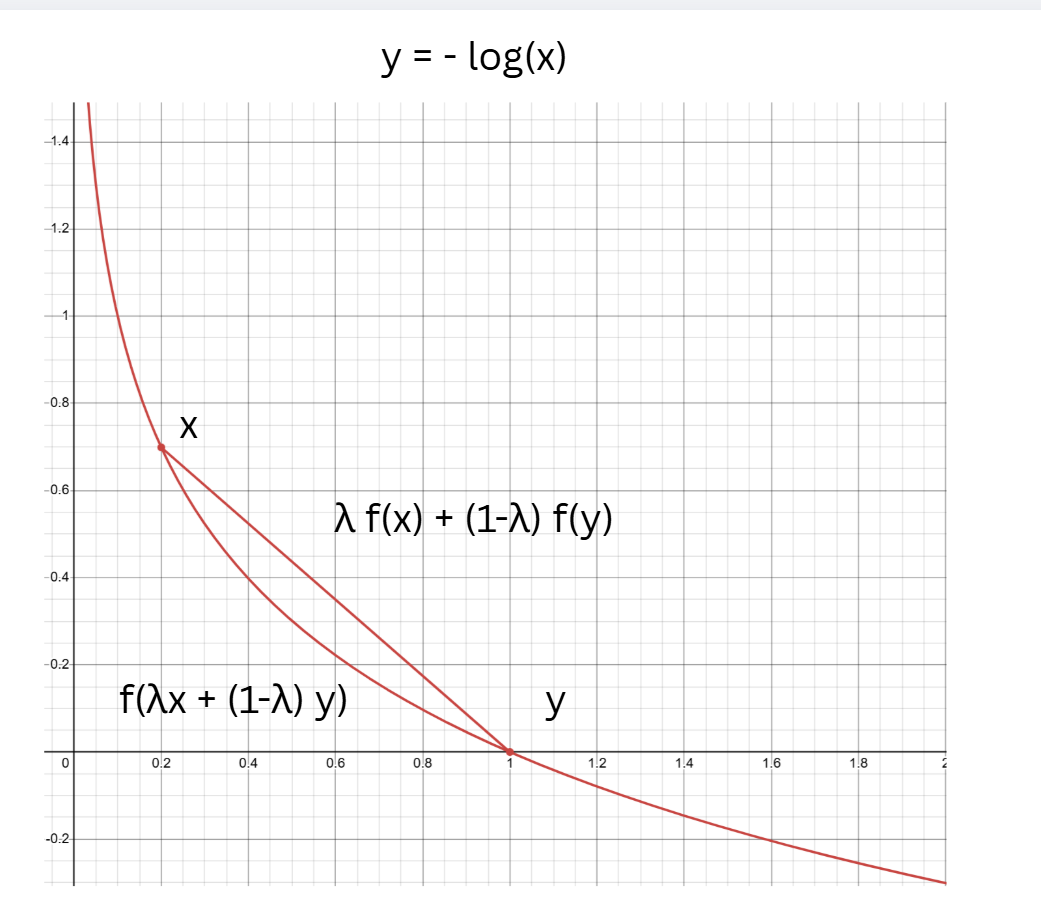


3.2) Show that if $f:\mathbb{R}^{n} \rightarrow \mathbb{R}$ is convex then

$$
f\left(\sum_{l=1}^{m}\lambda_{l}{\bf x}_{l}\right) \leq \sum_{l=1}^{m}\lambda_{l}f({\bf x}_{l}), ~ \lambda_{l}\in[0,1], ~\sum_{l=1}^{m}\lambda_{l} = 1.
$$

Note, this is a version of what is known as *Jensen's Inequality*.  

### Answer:

We prove Jensen's inequality by induction on $m$.

**Base case ($m=2$):** By the definition of convexity,

$$
f(\lambda_1 x_1 + \lambda_2 x_2)
\leq \lambda_1 f(x_1) + \lambda_2 f(x_2),
$$

where $\lambda_1+\lambda_2=1$.

**Inductive hypothesis:** Assume the inequality holds for $m=k$.

**Inductive step ($m=k+1$):** Let

$$
S = \sum_{i=1}^{k}\lambda_i = 1-\lambda_{k+1}.
$$

For $S>0$, define

$$
z = \sum_{i=1}^{k}\frac{\lambda_i}{S}x_i.
$$

Since $\sum_{i=1}^{k}\frac{\lambda_i}{S}=1$, we may apply
convexity followed by the inductive hypothesis:

$$
\begin{aligned}
f\left(\sum_{i=1}^{k+1}\lambda_i x_i\right)
&= f(Sz+\lambda_{k+1}x_{k+1})\\
&\leq S f(z)+\lambda_{k+1}f(x_{k+1})\\
&\leq S\sum_{i=1}^{k}\frac{\lambda_i}{S}f(x_i)
+\lambda_{k+1}f(x_{k+1})\\
&= \sum_{i=1}^{k+1}\lambda_i f(x_i).
\end{aligned}
$$

NOTE: We can apply the inductive hypothesis to z in f(z) since normalized weights sum to 1 so we can use it for k vectors, which is what enables us to 

If $S=0$, then $\lambda_1=\cdots=\lambda_k=0$
and $\lambda_{k+1}=1$, so the inequality holds
with equality.

Thus, by induction, Jensen's inequality holds
for all integers $m\geq 2$.

### NOTE: Did not attempt last two. Will attempt to solve over weekend :)

3.3) For the Kullback-Leibler distance above, we can write 

$$
D_{KL}({\bf p}||{\bf q}) = \sum_{k=1}^{C}p_{k}\left(-\log\frac{q_{k}}{p_{k}}\right).
$$

Using the inequality above, show that 

$$
D_{KL}({\bf p}||{\bf q}) \geq 0
$$

3.4) Show that $D_{KL}({\bf p}||{\bf q})=0$ if and only if $p_{k} = q_{k}$ for all $k$.  Clearly one direction of this is straightforward.  The other way, i.e. show that $D_{KL}({\bf p}||{\bf q})=0$ implies ${\bf p}={\bf q}$ is more challenging.  In this direction, you want to first identify the set $\tilde{{\bf K}}$ of indices $k$ such that $p_{k} > 0$.  Per our conventions then, we have, assuming $D_{KL}({\bf p}||{\bf q})=0$, that 

$$
0 = \sum_{k\in\tilde{{\bf K}}}p_{k}\log \left(\frac{q_{k}}{p_{k}}\right).
$$

Proceed from here.  